# ZIMAGER simulation

In [12]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np

import scopesim as sim
import scopesim_templates as sim_tp
from scopesim.source.source_templates import ab_spectrum

from zs_scopesim_tools.plots import PlotScene

from zs_scopesim_tools.helpers import (disable_scopesim_top_level_catch, warning_prevent_sync_alt_ra_dec,
                                       ignore_warnings, set_scopesim_log_level, make_local_output_dir, configure_irdb_path, timed, list_effects, simulate)

configure_irdb_path()  # REQUIRED the first time after installation, sets local IRDB directory path in ScopeSim
set_scopesim_log_level("info")  # set ScopeSim log toggles
disable_scopesim_top_level_catch()
ignore_warnings()

In [13]:
OUTDIR = make_local_output_dir(dirname="06_ZImager/")

In [14]:
zs_config = sim.UserCommands(use_instrument="ZShooter_v2", set_modes=["IMAGER"])
zs_config["!OBS.airmass"] = 1.1
zs_config["!OBS.seeing"] = 0.65
zs_config["!OBS.brightness"] = "dark"
zs_config["!OBS.imager_dit_u"] = 300
zs_config["!OBS.imager_ndit_u"] = 1
zs_config["!OBS.imager_dit_v"] = 300
zs_config["!OBS.imager_ndit_v"] = 1
zs_config["!OBS.imager_dit_z"] = 300
zs_config["!OBS.imager_ndit_z"] = 1


In [15]:
df = list_effects(zs_config)
df

,included,effect,class,config,selector,data file
0,True,atmo_transmission,TAPASTERCurve,MaunaKea (ATMO),,TER_maunakea_tapas.dat
1,True,continuum_emission,SkyBackgroundTERCurve,MaunaKea (ATMO),,
2,True,airglow_and_interline_continuum,PalaceAirglowEmission,MaunaKea (ATMO),,
3,True,seeing_psf,AOEnhanceablePSF,MaunaKea (ATMO),,
4,True,adc_residuals,ADCShift,MaunaKea (ATMO),,adc_residuals.dat
5,True,telescope_reflection,SurfaceList,keck (TEL),,LIST_keck_mirrors.dat
6,True,preoptics,SurfaceList,ZIMAGE (INST),,optics/LIST_zimage_common_optics.dat
7,True,dichroic_tree,DichroicTree,ZIMAGE (INST),,
8,True,channel_optics_selector,SelectorWheel,ZIMAGE (INST),,
9,True,filter_wheel_selector,SelectorWheel,ZIMAGE (INST),,


In [16]:
zs_config['!OBS']


[0] mapping contents:
├─instrument: ZShooter_v2
├─modes: ['IMAGER']
├─pupil_angle: 0
├─object: Test
├─az: 0.0
├─airmass: 1.1
├─seeing: 0.65
├─brightness: dark
├─dit_blue: 300.0
├─ndit_blue: 1
├─dit_green: 300.0
├─ndit_green: 1
├─dit_red: 300.0
├─ndit_red: 1
├─dit_yj: 300.0
├─ndit_yj: 1
├─dit_h: 300.0
├─ndit_h: 1
├─dit_k: 300.0
├─ndit_k: 1
├─imager_dit_u: 300
├─imager_ndit_u: 1
├─imager_dit_v: 300
├─imager_ndit_v: 1
├─imager_dit_z: 300
└─imager_ndit_z: 1

[1] mapping contents:

In [17]:
source = sim_tp.stars(filter_name='V', amplitudes=[25, 25, 25], spec_types=['B1V', 'G1V', 'M1V'], x=[-50, 0, 50], y=[0., 0., 0.])
ab_mag = 23
source.fields[0].spectra[4] = ab_spectrum(mag=23)
source.fields[0].field.add_row((0., 25., 4, 1., 'AB'))

In [18]:
zs, hdul = simulate(zs_config, source=source, hide_progress_bars=True)
zs_sky, hdul_sky = simulate(zs_config, source=None, hide_progress_bars=True)

astar.scopesim.utils - Brightness level supplied instead of time, dark
astar.scopesim.utils - Setting coordinates from alt/airmass, location and obstime input.
astar.scopesim.utils - Brightness level supplied instead of time, dark
astar.scopesim.utils - Setting coordinates from alt/airmass, location and obstime input.
astar.scopesim.utils - Brightness level supplied instead of time, dark
astar.scopesim.utils - Setting coordinates from alt/airmass, location and obstime input.
astar.scopesim.utils - Brightness level supplied instead of time, dark
astar.scopesim.utils - Setting coordinates from alt/airmass, location and obstime input.
astar.scopesim.utils - Brightness level supplied instead of time, dark
astar.scopesim.utils - Setting coordinates from alt/airmass, location and obstime input.
astar.scopesim.effects.psfs.analytical - dict supplied for FWHM
astar.scopesim.effects.psfs.analytical - seeing and pivot supplied, using natural scale seeing law
astar.scopesim.utils - Brightness lev

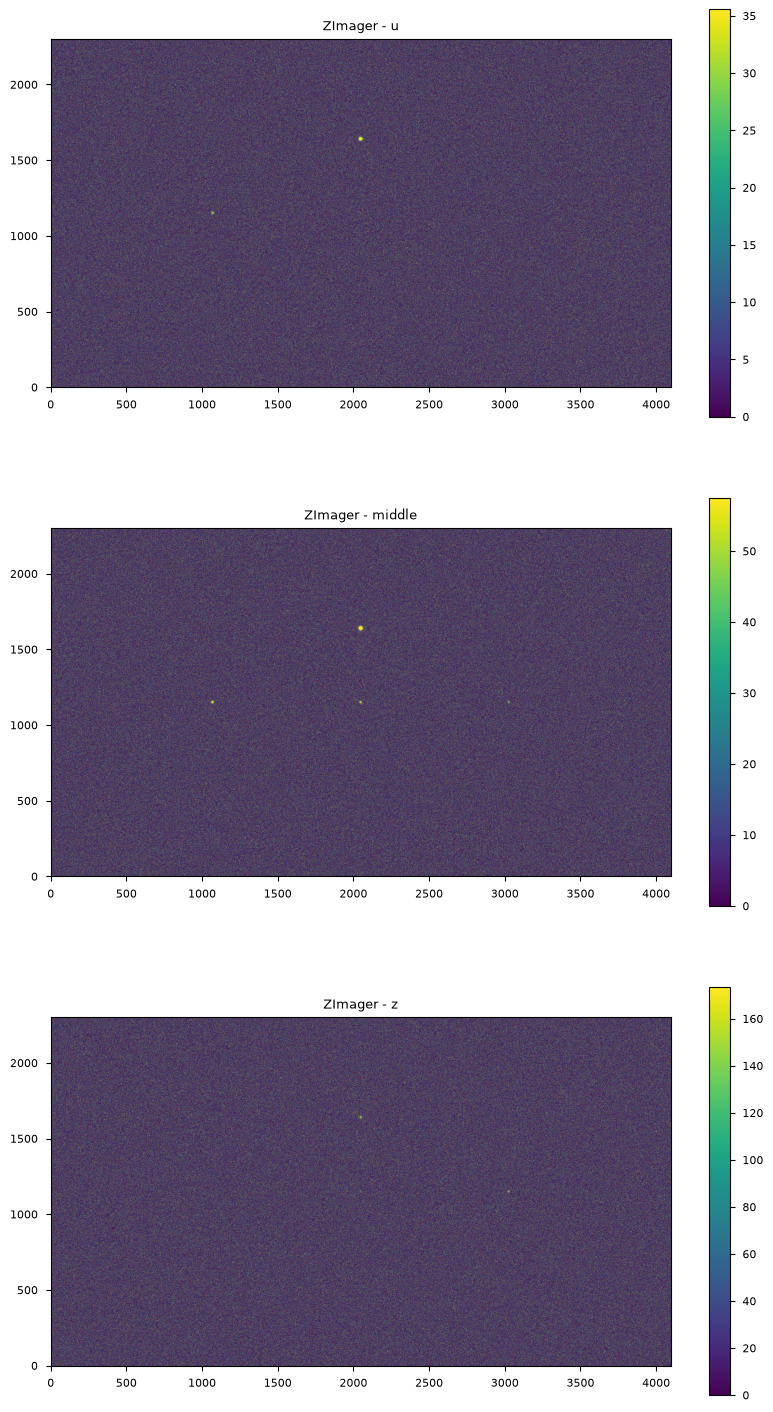

In [19]:
fig, ax = plt.subplots(3, 1, figsize=(10, 18))
for i, (hdu, hdu_sky) in enumerate(zip(hdul, hdul_sky)):
    dat = hdu[1].data - hdu_sky[1].data
    vmin, vmax = np.percentile(dat.clip(0), [5, 95])
    im = ax[i].imshow(dat.clip(0), origin='lower', vmin=vmin, vmax=vmax)
    plt.colorbar(im, ax=ax[i])
ax[0].set_title('ZImager - u')
ax[1].set_title('ZImager - middle')
ax[2].set_title('ZImager - z');

In [21]:
from IPython.display import HTML, display
from astropy.stats import sigma_clip
from astropy.table import Table
from astropy.wcs import WCS
from scopesim.optics.image_plane_utils import pix2val, val2pix

stars = source.fields[0].field
photometry = Table({'spec_type': stars['spec_types']})
for arm, hdu, fov in zip(['u', 'v', 'z'], hdul, zs._last_fovs):
    dat = hdu[1].data

    # Follow the simulation's sky -> focal-plane mm -> detector-pixel transform.
    x_fov, y_fov = val2pix(fov.header, stars['x'].quantity.to_value(u.deg), stars['y'].quantity.to_value(u.deg))
    x_mm, y_mm = pix2val(fov.header, x_fov, y_fov, 'D')
    x_det, y_det = WCS(hdu[1].header, key='D').world_to_pixel_values(x_mm, y_mm)
    pixel_scale = np.sqrt(fov.pixel_area) * hdu[1].header['CDELT1D'] / fov.header['CDELT1D']
    fwhm = zs['seeing_psf'].fwhm(fov.wavelength)
    radius = (fwhm / pixel_scale).value
    halfwidth = int(np.ceil(3 * radius))

    fluxes = np.empty(len(stars))
    flux_errors = np.empty(len(stars))
    for j, (x, y) in enumerate(zip(x_det, y_det)):
        ix, iy = int(round(x)), int(round(y))
        cutout = dat[iy-halfwidth:iy+halfwidth+1, ix-halfwidth:ix+halfwidth+1]
        yy, xx = np.mgrid[iy-halfwidth:iy+halfwidth+1, ix-halfwidth:ix+halfwidth+1]
        r2 = (xx - x)**2 + (yy - y)**2
        aperture = r2 <= radius**2
        annulus = (r2 >= (2 * radius)**2) & (r2 <= (3 * radius)**2)
        background_pixels = sigma_clip(cutout[annulus], sigma=3).compressed()
        n_ap = aperture.sum()
        fluxes[j] = cutout[aperture].sum() - n_ap * background_pixels.mean()

        # The science-image annulus measures sky and detector noise for this exposure.
        # Include uncertainty in the local background mean; source shot noise is neglected.
        flux_errors[j] = background_pixels.std(ddof=1) * np.sqrt(n_ap + n_ap**2 / background_pixels.size)
    photometry[f'S/N {arm}'] = np.maximum(fluxes / flux_errors, 0)
    ab_flux = fluxes[-1]  # The last source is the flat AB calibrator.
    photometry[f'AB5 {arm}'] = ab_mag - 2.5 * np.log10(5 * flux_errors / ab_flux)

photometry = photometry[['spec_type', 'S/N u', 'S/N v', 'S/N z', 'AB5 u', 'AB5 v', 'AB5 z']]
for name in photometry.colnames[1:]:
    photometry[name].format = '.2f'
print(f'AB5 calibrated from the flat AB={ab_mag} source; background-dominated noise.')
display(HTML(''.join(photometry.pformat(html=True, show_dtype=False, show_unit=False))))

astar.scopesim.utils - Brightness level supplied instead of time, dark
astar.scopesim.utils - Setting coordinates from alt/airmass, location and obstime input.
astar.scopesim.utils - Brightness level supplied instead of time, dark
astar.scopesim.utils - Setting coordinates from alt/airmass, location and obstime input.
astar.scopesim.utils - Brightness level supplied instead of time, dark
astar.scopesim.utils - Setting coordinates from alt/airmass, location and obstime input.
AB5 calibrated from the flat AB=23 source; background-dominated noise.


spec_type,S/N u,S/N v,S/N z,AB5 u,AB5 v,AB5 z
B1V,24.51,36.55,1.67,26.25,26.96,24.57
G1V,4.36,25.52,5.05,26.26,26.96,24.57
M1V,0.26,14.90,14.65,26.24,26.97,24.55
AB,100.36,194.41,20.90,26.26,26.97,24.55
